# Лабораторна робота №3: Реалізація RAG-системи для витягування знань
## Частина 1: Підготовка, аудит та чанкінг текстового корпусу знань

**Дисципліна:** Нейромережеві технології і системи  
**Тема:** Реалізація RAG-системи для витягування знань  
**Варіант:** №2 — Chroma + Markdown / Текст  
**Предметна область корпусу:** Практичний життєвий цикл Machine Learning систем: від підготовки даних до моніторингу та реагування на інциденти  

---

### Мета першого етапу:
1. Дослідити склад та цілісність підготовленого корпусу знань, що складається з 8 тематичних документів у форматах `.md` та `.txt`.
2. Реалізувати завантаження документів за допомогою спеціалізованого завантажувача `DirectoryLoader` бібліотеки LangChain із налаштуванням підтримки різних розширень.
3. Провести глибокий аудит корпусу: перевірку розширень, обчислення криптографічних контрольних сум SHA-256, аналіз кількості символів, слів, рядків та відсутності порожніх чи дубльованих файлів.
4. Дослідити поведінку алгоритму розбиття тексту `RecursiveCharacterTextSplitter` для трьох різних конфігурацій розміру чанка та перекриття (`chunk_size` / `chunk_overlap`).
5. Зберегти детальні метадані для кожного фрагмента (`source`, `type`, `chunk_id`, `document_id`) з метою забезпечення суворого відстеження джерел (provenance) на етапах векторного пошуку та генерації відповідей.

## 1. Діагностика програмного середовища та залежностей

Перед початком роботи перевіримо версії встановлених бібліотек, доступність обчислювальних ресурсів та стан системних модулів. Для варіанта №2 обов'язковими є бібліотеки `langchain`, `langchain-community`, `langchain-text-splitters`, `chromadb` та `sentence-transformers`.

In [1]:
import warnings
warnings.filterwarnings("ignore", message=".*IProgress not found.*")
warnings.filterwarnings("ignore", category=DeprecationWarning)

import sys
import os
import platform
import torch
import langchain
import chromadb
import sentence_transformers
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

print(f"Python version:      {platform.python_version()}")
print(f"Platform:            {platform.system()} {platform.release()}")
print(f"PyTorch version:     {torch.__version__}")
print(f"CUDA Available:      {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU Device:          {torch.cuda.get_device_name(0)}")
print(f"LangChain version:   {langchain.__version__}")
print(f"ChromaDB version:    {chromadb.__version__}")
print(f"Sentence-Transf.:    {sentence_transformers.__version__}")
print(f"Pandas version:      {pd.__version__}")

Python version:      3.13.5
Platform:            Windows 11
PyTorch version:     2.11.0+cu128
CUDA Available:      True
GPU Device:          NVIDIA GeForce RTX 3050 Laptop GPU
LangChain version:   1.5.0
ChromaDB version:    1.5.9
Sentence-Transf.:    6.1.0
Pandas version:      2.3.2


## 2. Завантаження корпусу знань через LangChain `DirectoryLoader`

Методичні вказівки вимагають завантаження 5–8 документів через `DirectoryLoader` із використанням відповідних завантажувачів для різних розширень файлів.

У нашому проєкті база знань містить 8 документів:
- 6 файлів у форматі Markdown (`.md`): концептуальні конспекти життєвого циклу ML (Data Quality, Feature Engineering, Training, Validation, Deployment, Monitoring);
- 2 файли у форматі звичайного тексту (`.txt`): регламенти реагування на інциденти (Incident Response) та політики безпеки й відтворюваності (Security & Reproducibility).

Оскільки обидва типи файлів є текстовими, але мають різні розширення, ми налаштовуємо `DirectoryLoader` з використанням `TextLoader(encoding='utf-8')` для забезпечення коректної обробки спецсимволів і математичної розмітки.

In [2]:
import warnings
from pathlib import Path

with warnings.catch_warnings():
    warnings.simplefilter("ignore", DeprecationWarning)
    from langchain_community.document_loaders import DirectoryLoader, TextLoader


def resolve_lab_dir() -> Path:
    cwd = Path.cwd().resolve()
    for candidate in [cwd, *cwd.parents]:
        if (candidate / "data" / "knowledge_base").exists() and candidate.name == "lab3_chroma_rag":
            return candidate
        if (candidate / "lab3_chroma_rag" / "data" / "knowledge_base").exists():
            return candidate / "lab3_chroma_rag"
    return cwd


def rel_path(path: Path) -> str:
    try:
        return path.resolve().relative_to(LAB_DIR).as_posix()
    except ValueError:
        return path.name


LAB_DIR = resolve_lab_dir().resolve()
KB_DIR = (LAB_DIR / "data" / "knowledge_base").resolve()
assert KB_DIR.exists(), f"Директорія бази знань не знайдена: {rel_path(KB_DIR)}"

print(f"Робочий модуль: {LAB_DIR.name}")
print(f"База знань:     {rel_path(KB_DIR)}")

md_loader = DirectoryLoader(str(KB_DIR), glob="*.md", loader_cls=TextLoader, loader_kwargs={"encoding": "utf-8"})
txt_loader = DirectoryLoader(str(KB_DIR), glob="*.txt", loader_cls=TextLoader, loader_kwargs={"encoding": "utf-8"})

md_docs = md_loader.load()
txt_docs = txt_loader.load()
all_raw_docs = md_docs + txt_docs
all_raw_docs.sort(key=lambda d: Path(d.metadata["source"]).name)

print(f"Завантажено документів: {len(all_raw_docs)} (Markdown: {len(md_docs)}, Text: {len(txt_docs)})")

Робочий модуль: lab3_chroma_rag
База знань:     data/knowledge_base
Завантажено документів: 8 (Markdown: 6, Text: 2)


## 3. Криптографічний та статистичний аудит корпусу

Надійність RAG-системи безпосередньо залежить від чистоти та відтворюваності даних. Здійснимо комплексний аудит:
1. Перевірка розширень файлів (мають бути виключно `.md` та `.txt`).
2. Обчислення гешу SHA-256 для кожного файлу — це гарантує захист від неконтрольованої модифікації або пошкодження тексту.
3. Підрахунок символів, слів, рядків та перевірка відсутності порожніх файлів.
4. Перевірка відсутності дублікатів файлів за вмістом.

In [3]:
import hashlib

audit_records = []
content_hashes = set()

for doc in all_raw_docs:
    path = Path(doc.metadata["source"])
    content = doc.page_content
    sha256_hash = hashlib.sha256(content.encode("utf-8")).hexdigest()
    is_duplicate = sha256_hash in content_hashes
    content_hashes.add(sha256_hash)

    words = content.split()
    lines = content.splitlines()

    audit_records.append({
        "filename": path.name,
        "extension": path.suffix.lower(),
        "type": path.suffix.lower().replace(".", ""),
        "characters": len(content),
        "words": len(words),
        "lines": len(lines),
        "sha256": sha256_hash[:16] + "...",
        "full_sha256": sha256_hash,
        "is_empty": len(content.strip()) == 0,
        "is_duplicate": is_duplicate,
    })

df_audit = pd.DataFrame(audit_records)
print(f"Унікальних документів: {len(content_hashes)} із {len(all_raw_docs)} (порожніх: {int(df_audit['is_empty'].sum())}, дублікатів: {int(df_audit['is_duplicate'].sum())})")
assert not df_audit["is_empty"].any(), "Увага! Виявлено порожні файли в корпусі!"
assert not df_audit["is_duplicate"].any(), "Увага! Виявлено дублікати документів!"

display_cols = ["filename", "type", "characters", "words", "lines", "sha256", "is_empty"]
display(df_audit[display_cols])

out_tables = LAB_DIR / "outputs" / "tables"
out_tables.mkdir(parents=True, exist_ok=True)
audit_csv_path = out_tables / "corpus_audit_report.csv"
df_audit.to_csv(audit_csv_path, index=False)
print(f"Детальний аудит із повними SHA-256 збережено у {rel_path(audit_csv_path)}")

Унікальних документів: 8 із 8 (порожніх: 0, дублікатів: 0)


,filename,type,characters,words,lines,sha256,is_empty
0,01_data_quality.md,md,3511,439,27,cca1a7976f7fb048...,False
1,02_feature_engineering.md,md,3209,385,30,cd4c22b38609e5ea...,False
2,03_model_training.md,md,2882,362,27,254464141091f0ae...,False
3,04_validation_and_metrics.md,md,2673,319,31,6be0ca7d7f011ef7...,False
4,05_deployment_architecture.md,md,2771,343,26,7d3981ba5e4579bb...,False
5,06_model_monitoring.md,md,2637,326,34,06fd4be3e722d1e8...,False
6,07_incident_response.txt,txt,3125,406,41,43d14a59dd85a80d...,False
7,08_security_and_reproducibility.txt,txt,3076,356,31,b1e27b054edb00f2...,False


Детальний аудит із повними SHA-256 збережено у outputs/tables/corpus_audit_report.csv


### 3.1 Візуалізація обсягу документів корпусу

Побудуємо діаграму розподілу довжин документів за кількістю слів та символів для наочного порівняння інформаційної місткості окремих розділів.

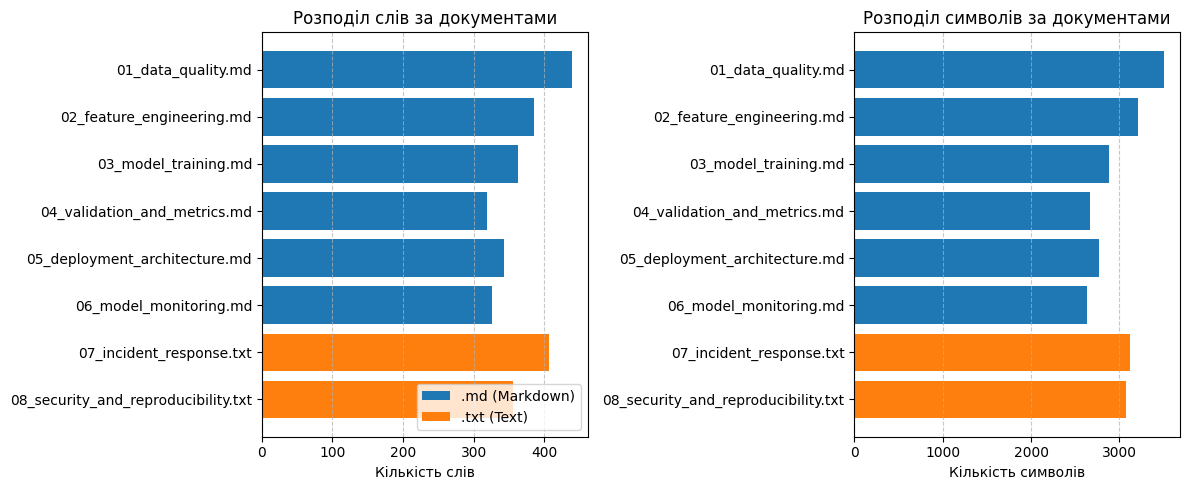

Графік збережено у outputs/figures/corpus_document_lengths.png


In [4]:
out_figures = LAB_DIR / "outputs" / "figures"
out_figures.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
colors = ['#1f77b4' if t == 'md' else '#ff7f0e' for t in df_audit['type']]
bars = plt.barh(df_audit['filename'], df_audit['words'], color=colors)
plt.xlabel('Кількість слів')
plt.title('Розподіл слів за документами')
plt.gca().invert_yaxis()
plt.grid(axis='x', linestyle='--', alpha=0.7)

# Додамо легенду типів
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='#1f77b4', label='.md (Markdown)'),
                   Patch(facecolor='#ff7f0e', label='.txt (Text)')]
plt.legend(handles=legend_elements, loc='lower right')

plt.subplot(1, 2, 2)
plt.barh(df_audit['filename'], df_audit['characters'], color=colors)
plt.xlabel('Кількість символів')
plt.title('Розподіл символів за документами')
plt.gca().invert_yaxis()
plt.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
corpus_fig_path = out_figures / "corpus_document_lengths.png"
plt.savefig(corpus_fig_path, dpi=300)
plt.show()
print(f"Графік збережено у {rel_path(corpus_fig_path)}")


## 4. Дослідження стратегій розбиття тексту (Chunking)

### 4.1 Теоретичне обґрунтування чанкінгу

Векторні моделі трансформерів (зокрема `all-MiniLM-L6-v2`) мають обмежене контекстне вікно (256 або 512 токенів). Якщо подати в модель занадто довгий текст, він або відсікається, або інформація «розмазується» по одному вектору фіксованого розміру ($d = 384$).

- **Занадто малий chunk**: фрагмент втрачає семантичний контекст, посилання на об'єкти та зв'язки причини й наслідку (fragmentation bias).
- **Занадто великий chunk**: у фрагмент потрапляє кілька непов'язаних ідей, зменшується точність косинусної близькості векторів до специфічного запиту користувача, зростає кількість "шуму" для LLM.
- **Роль перекриття (`chunk_overlap`)**: створює ковзне вікно (sliding window), що запобігає розриву критично важливих речень або формул на межі двох сусідніх фрагментів.

Для `RecursiveCharacterTextSplitter` пріоритет розділювачів за замовчуванням:
$$["\n\n", "\n", " ", ""]$$
Це дозволяє розбивати текст природним шляхом: спочатку по абзацах, потім по рядках, потім по словах і в крайньому випадку по символах.

Дослідимо 3 конфігурації:
1. **Конфігурація 1 (Small):** `chunk_size = 400`, `chunk_overlap = 60`
2. **Конфігурація 2 (Medium - Baseline):** `chunk_size = 700`, `chunk_overlap = 100`
3. **Конфігурація 3 (Large):** `chunk_size = 1000`, `chunk_overlap = 150`

In [5]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

configs = [
    {"name": "Small (400/60)", "chunk_size": 400, "chunk_overlap": 60},
    {"name": "Medium (700/100)", "chunk_size": 700, "chunk_overlap": 100},
    {"name": "Large (1000/150)", "chunk_size": 1000, "chunk_overlap": 150},
]

chunk_experiment_results = []
splitters_data = {}

for cfg in configs:
    splitter = RecursiveCharacterTextSplitter(
        chunk_size=cfg["chunk_size"],
        chunk_overlap=cfg["chunk_overlap"],
        length_function=len,
        separators=["\n\n", "\n", " ", ""]
    )
    chunks = splitter.split_documents(all_raw_docs)
    lengths = [len(c.page_content) for c in chunks]
    words_count = [len(c.page_content.split()) for c in chunks]
    
    splitters_data[cfg["name"]] = {
        "chunks": chunks,
        "lengths": lengths,
        "words": words_count
    }
    
    chunk_experiment_results.append({
        "Config": cfg["name"],
        "Chunk Size": cfg["chunk_size"],
        "Overlap": cfg["chunk_overlap"],
        "Total Chunks": len(chunks),
        "Min Length": min(lengths),
        "Max Length": max(lengths),
        "Mean Length": round(np.mean(lengths), 2),
        "Median Length": round(np.median(lengths), 2),
        "Std Dev": round(np.std(lengths), 2),
        "Mean Words": round(np.mean(words_count), 2)
    })

df_chunk_exp = pd.DataFrame(chunk_experiment_results)
print("Порівняння конфігурацій розбиття тексту:")
display(df_chunk_exp)
exp_csv_path = out_tables / "chunking_experiments.csv"
df_chunk_exp.to_csv(exp_csv_path, index=False)
print(f"Таблицю експериментів збережено у {rel_path(exp_csv_path)}")


Порівняння конфігурацій розбиття тексту:


,Config,Chunk Size,Overlap,Total Chunks,Min Length,Max Length,Mean Length,Median Length,Std Dev,Mean Words
0,Small (400/60),400,60,92,39,399,261.36,267.5,95.62,32.32
1,Medium (700/100),700,100,55,80,695,434.76,478.0,179.47,53.65
2,Large (1000/150),1000,150,34,280,990,700.71,776.5,216.96,86.35


Таблицю експериментів збережено у outputs/tables/chunking_experiments.csv


### 4.2 Порівняння розподілу довжин чанків

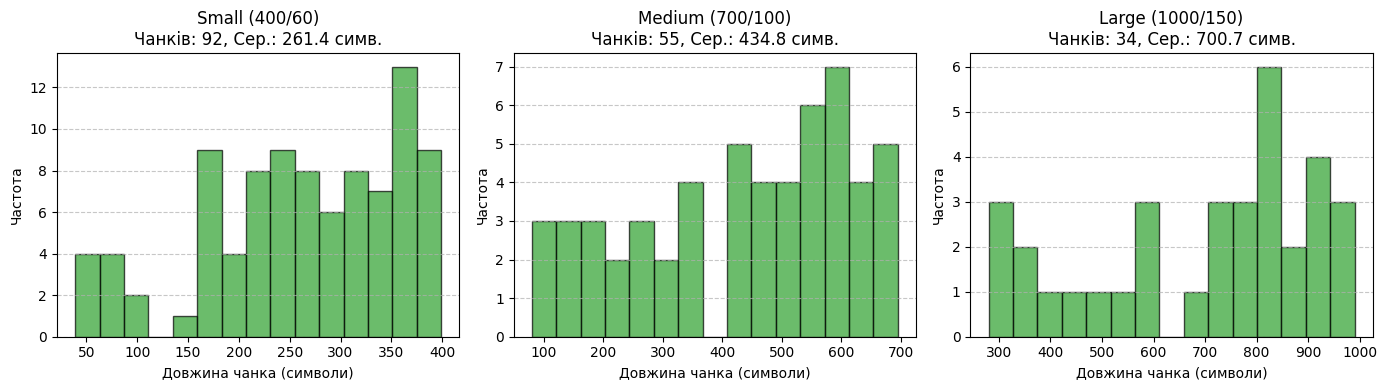

Гістограми збережено у outputs/figures/chunk_size_distribution.png


In [6]:
plt.figure(figsize=(14, 4))

for idx, (cfg_name, data) in enumerate(splitters_data.items(), 1):
    plt.subplot(1, 3, idx)
    plt.hist(data["lengths"], bins=15, color='#2ca02c', edgecolor='black', alpha=0.7)
    plt.title(f"{cfg_name}\nЧанків: {len(data['lengths'])}, Сер.: {np.mean(data['lengths']):.1f} симв.")
    plt.xlabel('Довжина чанка (символи)')
    plt.ylabel('Частота')
    plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
dist_fig_path = out_figures / "chunk_size_distribution.png"
plt.savefig(dist_fig_path, dpi=300)
plt.show()
print(f"Гістограми збережено у {rel_path(dist_fig_path)}")


## 5. Фіналізація розбиття та збагачення метаданими

**Обґрунтування вибору:** Для моделі ембеддингів `sentence-transformers/all-MiniLM-L6-v2` робочий баланс між збереженням локального контексту та гранулярністю пошуку забезпечує **Конфігурація 2 (`chunk_size = 700`, `chunk_overlap = 100`)**. На досліджуваному корпусі вона формує **55 чанків** із середньою довжиною **434.8 символів** (медіана — **478.0** символів, середнє — **~53.7 слів**, діапазон довжин — **80–695** символів).

### 5.1 Прив'язка метаданих (Metadata Provenance)
Для відтворюваної та переносимої індексації кожен чанк містить структуровані поля без прив'язки до локальних абсолютних шляхів робочої станції:
- `source`: коротка канонічна назва файлу-джерела для цитувань та фільтрів (`01_data_quality.md`);
- `relative_path`: портативний відносний шлях у межах модуля (`data/knowledge_base/01_data_quality.md`);
- `filename`: назва файлу;
- `type`: тип документа (`md` або `txt`);
- `document_id`: ідентифікатор документа (`01_data_quality`);
- `chunk_id`: глобально унікальний ідентифікатор фрагмента (`01_data_quality_chunk_001`);
- `chunk_index`, `total_chunks_in_doc`, `char_count`, `word_count`: структурні атрибути фрагмента.

In [8]:
selected_splitter = RecursiveCharacterTextSplitter(
    chunk_size=700,
    chunk_overlap=100,
    length_function=len,
    separators=["\n\n", "\n", " ", ""],
)

final_chunks = []
chunk_metadata_records = []

# Розбиваємо кожен документ окремо, щоб контролювати нумерацію всередині документа
for doc in all_raw_docs:
    path = Path(doc.metadata["source"])
    doc_id = path.stem
    doc_ext = path.suffix.lower().replace(".", "")
    portable_rel_path = f"data/knowledge_base/{path.name}"

    doc_chunks = selected_splitter.split_documents([doc])

    for i, chunk in enumerate(doc_chunks):
        chunk_id = f"{doc_id}_chunk_{i+1:03d}"
        enriched_meta = {
            "source": path.name,
            "relative_path": portable_rel_path,
            "filename": path.name,
            "type": doc_ext,
            "document_id": doc_id,
            "chunk_id": chunk_id,
            "chunk_index": i + 1,
            "total_chunks_in_doc": len(doc_chunks),
            "char_count": len(chunk.page_content),
            "word_count": len(chunk.page_content.split()),
        }
        chunk.metadata = enriched_meta
        final_chunks.append(chunk)
        chunk_metadata_records.append(enriched_meta)

print(f"Сформовано фінальних збагачених чанків: {len(final_chunks)}")

df_final_chunks = pd.DataFrame(chunk_metadata_records)
print(
    f"Фактичні метрики корпусу: mean={df_final_chunks['char_count'].mean():.2f} симв. "
    f"(median={df_final_chunks['char_count'].median():.1f}, min={df_final_chunks['char_count'].min()}, max={df_final_chunks['char_count'].max()}), "
    f"mean_words={df_final_chunks['word_count'].mean():.2f}"
)

display(df_final_chunks[["chunk_id", "source", "type", "chunk_index", "total_chunks_in_doc", "char_count", "word_count"]].head(8))

chunks_csv_path = out_tables / "chunks_summary.csv"
df_final_chunks.to_csv(chunks_csv_path, index=False)
print(f"Повний реєстр усіх {len(df_final_chunks)} чанків збережено у {rel_path(chunks_csv_path)}")

Сформовано фінальних збагачених чанків: 55
Фактичні метрики корпусу: mean=434.76 симв. (median=478.0, min=80, max=695), mean_words=53.65


,chunk_id,source,type,chunk_index,total_chunks_in_doc,char_count,word_count
0,01_data_quality_chunk_001,01_data_quality.md,md,1,8,536,62
1,01_data_quality_chunk_002,01_data_quality.md,md,2,8,478,65
2,01_data_quality_chunk_003,01_data_quality.md,md,3,8,491,58
3,01_data_quality_chunk_004,01_data_quality.md,md,4,8,290,39
4,01_data_quality_chunk_005,01_data_quality.md,md,5,8,544,70
5,01_data_quality_chunk_006,01_data_quality.md,md,6,8,634,82
6,01_data_quality_chunk_007,01_data_quality.md,md,7,8,165,20
7,01_data_quality_chunk_008,01_data_quality.md,md,8,8,360,43


Повний реєстр усіх 55 чанків збережено у outputs/tables/chunks_summary.csv


### 5.2 Візуальна інспекція зразків чанків (Markdown vs TXT)

Переконаємося, що фрагменти зберігають змістовну цілісність як для структурованих Markdown-файлів, так і для текстових регламентів.

In [10]:
sample_md = next(c for c in final_chunks if c.metadata["type"] == "md")
sample_txt = next(c for c in final_chunks if c.metadata["type"] == "txt")

df_samples_meta = pd.DataFrame([sample_md.metadata, sample_txt.metadata])[
    ["chunk_id", "source", "relative_path", "type", "char_count", "word_count"]
]
display(df_samples_meta)


def render_chunk_preview(chunk) -> str:
    m = chunk.metadata
    return (
        f"**Зразок ({m['type'].upper()}) — `{m['chunk_id']}`** "
        f"(джерело: `{m['relative_path']}`, символів: {m['char_count']}):\n\n"
        f"```text\n{chunk.page_content.strip()}\n```"
    )


display(Markdown(render_chunk_preview(sample_md) + "\n\n---\n\n" + render_chunk_preview(sample_txt)))

,chunk_id,source,relative_path,type,char_count,word_count
0,01_data_quality_chunk_001,01_data_quality.md,data/knowledge_base/01_data_quality.md,md,536,62
1,07_incident_response_chunk_001,07_incident_response.txt,data/knowledge_base/07_incident_response.txt,txt,430,52


**Зразок (MD) — `01_data_quality_chunk_001`** (джерело: `data/knowledge_base/01_data_quality.md`, символів: 536):

```text
# Production Machine Learning Data Quality and Validation Frameworks

## 1. Fundamental Principles of Training Data Quality
Data quality is the foundational prerequisite for reproducible and generalizable machine learning systems. In high-throughput predictive architectures, downstream model degradation is predominantly driven by upstream data anomalies rather than algorithmic deficiencies. High-integrity data engineering requires systematic validation of completeness, uniqueness, timeliness, validity, and statistical consistency.
```

---

**Зразок (TXT) — `07_incident_response_chunk_001`** (джерело: `data/knowledge_base/07_incident_response.txt`, символів: 430):

```text
PRODUCTION MACHINE LEARNING INCIDENT RESPONSE PROTOCOLS AND MITIGATION PLAYBOOKS

1. Incident Classification and Severity Levels
Machine learning incidents differ fundamentally from traditional software defects. While microservice crashes trigger HTTP 5xx codes, model failures typically present as "silent degradation" where inference endpoints return HTTP 200 OK with mathematically degraded, nonsensical, or biased predictions.
```

## 6. Серіалізація оброблених даних для наступного етапу

Для гарантування ідентичності вхідних даних між першим, другим та третім ноутбуками збережемо підготовлений список об'єктів `Document` у файл `chunks_prepared.json`.

In [11]:
import json

serialized_chunks = [
    {"page_content": c.page_content, "metadata": c.metadata}
    for c in final_chunks
]

for item in serialized_chunks:
    meta = item["metadata"]
    assert "full_path" not in meta, "Знайдено локальний full_path у метаданих чанка!"
    assert ":\\" not in str(meta) and "C:/" not in str(meta), f"Абсолютний шлях у метаданих: {meta}"

chunks_json_path = out_tables / "chunks_prepared.json"
with open(chunks_json_path, "w", encoding="utf-8") as f:
    json.dump(serialized_chunks, f, ensure_ascii=False, indent=2)

print(f"Збережено {len(serialized_chunks)} переносимих чанків у {rel_path(chunks_json_path)}")

Збережено 55 переносимих чанків у outputs/tables/chunks_prepared.json


## 7. Висновки першого етапу

1. **Цілісність корпусу:** Завантажено та верифіковано 8 тематичних документів (6 у форматі `.md` та 2 у форматі `.txt`). Криптографічний аудит підтвердив відсутність порожніх файлів і дублікатів; повні контрольні суми SHA-256 збережено у CSV-звіті (`outputs/tables/corpus_audit_report.csv`).
2. **Результати чанкінгу:** Експериментальне порівняння трьох конфігурацій показало, що конфігурація `chunk_size = 700`, `chunk_overlap = 100` формує 55 фрагментів із середньою довжиною **434.8 символів** (медіана 478.0, діапазон 80–695 символів) без обрізання на рівні слів.
3. **Портативні метадані:** Кожен чанк містить поля `source`, `relative_path`, `type`, `document_id` та `chunk_id` без машинно-специфічних абсолютних шляхів, що гарантує переносиму роботу ChromaDB, фільтрації метаданих та цитування у наступних ноутбуках.